# Prithvi-OpenET: inference on an example chip

Runs the three Prithvi-OpenET models (Opt., Opt.+F, Opt.+F+E), the OpenET emulator (stage 1, trained on OpenET Collection v2.1 over CONUS), on a 224 × 224 chip at 30 m.
Each model predicts the ET/PET ratio of the five OpenET members (DisALEXI, eeMETRIC, geeSEBAL, PT-JPL, SSEBop);
ET = ratio × MERRA-2 PET, and the maps show the five-head mean.

Before running: unzip the model zips from Zenodo (to be released) into `weights/` in the repository root (`<repo>/weights/`).
The Prithvi-OpenET models download their encoder (Prithvi-EO-2.0-300M-TL, about 1.3 GB) from Hugging Face on first use.
Runs on CPU in about a minute per model.

In [1]:
import json, logging, sys, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice without ipywidgets
logging.getLogger("albumentations").setLevel(logging.WARNING)

REPO = Path("../..").resolve()
sys.path.insert(0, str(REPO))
from prithvi_openet import example_inputs, load_model, predict

WEIGHTS = REPO / "weights"           # the model zips from Zenodo, unzipped here (see README)
EXAMPLES = REPO / "examples"

## Example chip

| Chip | Location | Month |
|---|---|---|
| `conus_T13TGE_2020-07` | MGRS T13TGE, eastern Colorado (centre-pivot irrigation) | July 2020 |
| `conus_T15SXU_2021-08` | MGRS T15SXU, irrigated cropland | August 2021 |
| `france_lamasquere_2021-07` | flux tower FR-Lam, Lamasquère, France (MGRS T31TCJ) | July 2021 |

In [2]:
CHIP = "conus_T13TGE_2020-07"
ex = np.load(EXAMPLES / f"{CHIP}.npz")

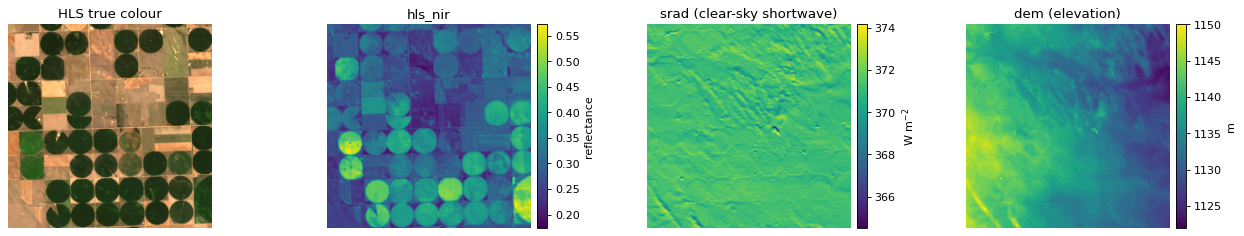

conus_T13TGE_2020-07: lat 40.5281, lon -102.2757, 2020-07, MGRS T13TGE, PET 216.5 mm/month


In [3]:
names = [str(n) for n in ex["channel_names"]]
raw = ex["inputs_raw"]                       # physical units, NaN where there is no HLS observation or a fill value
rgb = np.stack([raw[names.index(b)] for b in ("hls_b04", "hls_b03", "hls_b02")], -1)
rgb = np.clip(np.nan_to_num(rgb) / np.nanpercentile(rgb, 99), 0, 1)
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
fig.subplots_adjust(wspace=0.45)
panels = [("HLS true colour", None, ""), ("hls_nir", "hls_nir", "reflectance"),
          ("srad (clear-sky shortwave)", "srad", "W m$^{-2}$"), ("dem (elevation)", "dem", "m")]
for a, (title, ch, unit) in zip(ax, panels):
    cax = make_axes_locatable(a).append_axes("right", size="5%", pad=0.08)   # same panel size with or without a colour bar
    if ch is None:
        a.imshow(rgb); cax.axis("off")
    else:
        im = a.imshow(raw[names.index(ch)], cmap="viridis"); fig.colorbar(im, cax=cax, label=unit)
    a.set_title(title); a.axis("off")
plt.show()
md = json.loads(str(ex["metadata"]))
print(f"{CHIP}: lat {md['lat']:.4f}, lon {md['lon']:.4f}, {md['ym']}, MGRS {md['mgrs_tile']}, PET {float(ex['pet_mm']):.1f} mm/month")

## Predict with the three input configurations

`example_inputs` normalises the stored channel values with each model's own statistics (`config.json`), with the same
rules as in training.

In [4]:
models = ["prithvi_openet_opt", "prithvi_openet_opt_f", "prithvi_openet_opt_f_e"]
pred = {}
for m in models:
    model, cfg = load_model(WEIGHTS / m)
    pred[m] = predict(model, example_inputs(ex, cfg))
    stored = ex[f"pred_{m}_mean"]
    print(f"{cfg['display_name']:36s} mean ET {pred[m]['et_mean'].mean():6.1f} mm/month   "
          f"max |difference from stored prediction| {np.abs(pred[m]['et_mean'] - stored).max():.2e}")

Prithvi-OpenET (Opt.)                mean ET  139.0 mm/month   max |difference from stored prediction| 0.00e+00
Prithvi-OpenET (Opt.+F)              mean ET  131.5 mm/month   max |difference from stored prediction| 0.00e+00
Prithvi-OpenET (Opt.+F+E)            mean ET  134.1 mm/month   max |difference from stored prediction| 0.00e+00


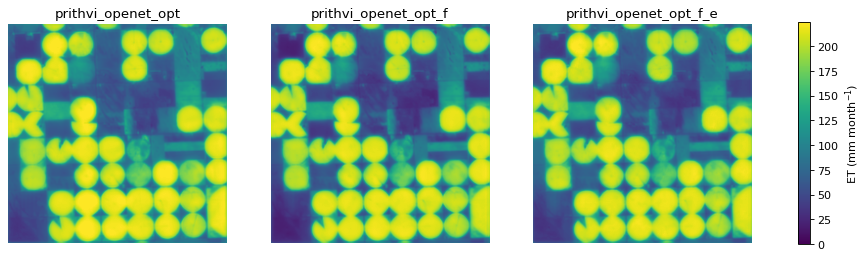

In [5]:
vmax = np.percentile(np.stack([p["et_mean"] for p in pred.values()]), 99.5)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, m in zip(ax, models):
    im = a.imshow(pred[m]["et_mean"], vmin=0, vmax=vmax, cmap="viridis"); a.set_title(m); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8, label="ET (mm month$^{-1}$)")
plt.show()

## The five OpenET-member heads (Prithvi-OpenET, Opt.+F+E)

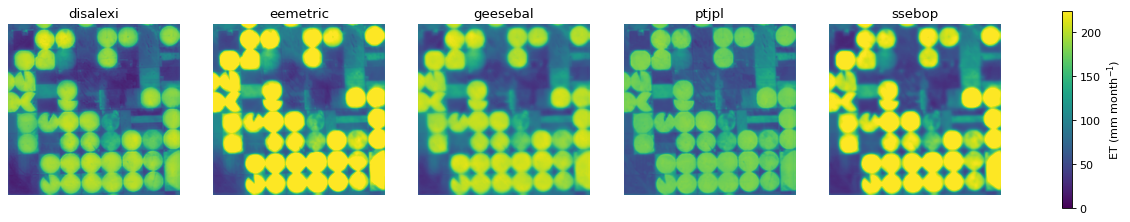

In [6]:
members = ["disalexi", "eemetric", "geesebal", "ptjpl", "ssebop"]
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, k, et in zip(ax, members, pred["prithvi_openet_opt_f_e"]["et_members"]):
    im = a.imshow(et, vmin=0, vmax=vmax, cmap="viridis"); a.set_title(k); a.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8, label="ET (mm month$^{-1}$)")
plt.show()